In [ ]:
import kagglehub
kagglehub.login()
path = kagglehub.competition_download('cats-and-dogs-plus-plus')

print("Path to competition files:", path)

Path to competition files: /root/.cache/kagglehub/competitions/cats-and-dogs-plus-plus


In [ ]:
import os
import pandas as pd

for root, dirs, files in os.walk(path):
    level = root.replace(path, "").count(os.sep)
    if level <= 1:
        print("  " * level + os.path.basename(root) + "/", f"({len(files)} файлів)")
        for f in files[:5]:
            print("  " * (level + 1) + f)

csvs = [f for f in os.listdir(path) if f.endswith(".csv")]
for c in csvs:
    print(f"\n=== {c} ===")
    df = pd.read_csv(os.path.join(path, c))
    print(df.shape)
    print(df.head())

cats-and-dogs-plus-plus/ (3 файлів)
  sample_submission.csv
  test.csv
  train.csv
  train/ (12260 файлів)
    8e75eb7fd6421c8a83c2d3a6bed6f4ce2282c16c.jpg
    d41922c1797c6a84d799b5a581c80b20ea9e6476.jpg
    c8dfaa3571f77ed508ff47107ee4bf6cfab9df5d.jpg
    f4624bfc725aa1551823086d2a53d139da8be97d.jpg
    cc86ce2c11eb81056a6363600241b6a1e7a6342c.jpg
  test/ (18390 файлів)
    428ff1cadc4624596c96592d1d49dcd9f4c10a54.jpg
    fec8374813560553797eec7fcf064e6966afa655.jpg
    d26228f7c52e62586d90abf6b0c0266c9033ed5d.jpg
    02feeabb5ec0837d4ebf0e2746ac4ad498ef1652.jpg
    5882fba2bccf75aaaa6d4c9623c2adf2e312c7ea.jpg

=== sample_submission.csv ===
(18390, 6)
                                   image_id  Cat  Dog  Moris  Motya  Biatrix
0  7e9de2837ab0f90176c0e6c2e30c2c136f1f00d9    1    1      1      1        1
1  11e8173dd91e7a00f8bdbc64067d6f167c9bbed2    1    1      1      1        1
2  415c62c8d85c0a13300ba25f4a5e6582eb468c31    1    1      1      1        1
3  4fbdedc390d83a9b264dc8e0ea8

In [ ]:
train_df = pd.read_csv(os.path.join(path, "train.csv"))
test_df = pd.read_csv(os.path.join(path, "test.csv"))

In [ ]:
train_df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 12260 entries, 0 to 12259
Data columns (total 6 columns):
 #   Column    Non-Null Count  Dtype 
---  ------    --------------  ----- 
 0   image_id  12260 non-null  object
 1   Cat       12260 non-null  int64 
 2   Dog       12260 non-null  int64 
 3   Moris     12260 non-null  int64 
 4   Motya     12260 non-null  int64 
 5   Biatrix   12260 non-null  int64 
dtypes: int64(5), object(1)
memory usage: 574.8+ KB


In [ ]:
persha_kartinka = train_df["image_id"][2]

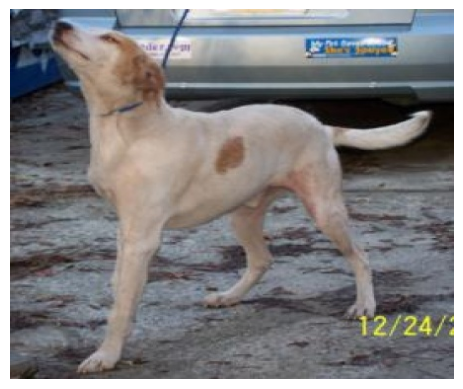

(375, 450, 3)
image_id    d29be872d012d8766c5942847d1d721788fd9511
Cat                                                0
Dog                                                1
Moris                                              0
Motya                                              0
Biatrix                                            0
Name: 2, dtype: object


In [ ]:
import cv2
import matplotlib.pyplot as plt

img = cv2.imread(os.path.join(path, "train", f"{persha_kartinka}.jpg"))
img = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)

plt.imshow(img)
plt.axis("off")
plt.show()

print(img.shape)
print(train_df.iloc[2])

,0
Cat,5077
Dog,5025
Moris,56
Motya,42
Biatrix,41


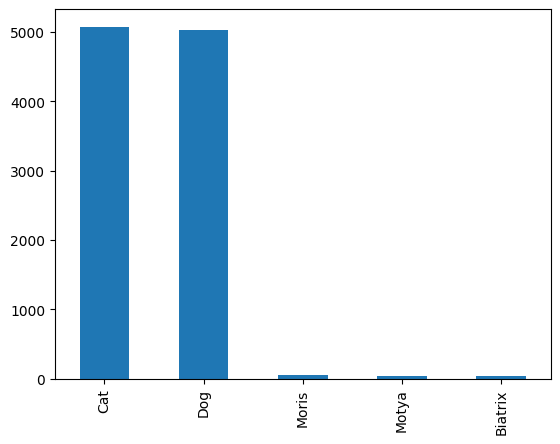

In [ ]:
labels = train_df.drop(columns = "image_id")

labels_res = labels.sum()

labels_res.plot.bar()

labels_res

In [ ]:
empty = labels[(labels['Biatrix'] == 0) & (labels['Cat'] == 0) & (labels['Dog'] == 0) & (labels['Motya'] == 0) & (labels['Moris'] == 0)]

empty.count()

,0
Cat,2162
Dog,2162
Moris,2162
Motya,2162
Biatrix,2162


In [ ]:
LABELS = ["Cat", "Dog", "Moris", "Motya", "Biatrix"]

train_df[LABELS].sum(axis=1).value_counts()

,count
1,9973
0,2162
2,111
3,10
4,4


In [ ]:
print(f"train count: {train_df['image_id'].count()}")
print(f"test count: {test_df.count()}")

train count: 12260
test count: image_id    18390
dtype: int64


In [ ]:
lab = train_df.drop(columns = "image_id")

lab = lab.sum(axis = 1)

lab[lab > 1].count()

np.int64(125)

In [ ]:
train_df.isna().sum()

,0
image_id,0
Cat,0
Dog,0
Moris,0
Motya,0
Biatrix,0


Here we have a clear class imbalance; because of this, we can't use simple metrics like accuracy. F1 macro looks like a good metric, as it gives equal weight to precision and recall and also equal weight to each class.

I see two alternative or additional metrics:
1. F-beta score. It depends on our purpose: for example, if precision is more important to us, we can add more weight to it in this metric.
2. PR curve. It can solve the problem that we don't know how confidently our model will classify; PR-AUC can help with this problem.